# GRANAP, 4: sensitivity analysis

**What you will learn:** rank the parameters by their effect on an output, first one at a time, then all together by
random sampling. Then compare the effects with the model's own randomness.

**You need:** tutorials 2 and 3. **Run time:** about 2 minutes.

A **sensitivity analysis** answers: *which parameters matter most for this output?* It tells which traits need an
accurate measurement, and which can stay at their defaults.

## 1. One at a time

Each size parameter is changed by −10 % and +10 % around its default, the others kept at their defaults. The relative
change of the outputs is recorded. The counts (numbers of layers or vessels) are left out, since 10 % of them is not
a whole number.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.granap.simulation import parameters, simulate

OUTPUTS = ["radius", "cells", "mean_vessel_diameter", "air_share"]
studied = [("stele", "thickness"), ("stele", "cell_diameter"), ("stele", "cell_diameter_center"),
           ("xylem", "vessel_diameter"), ("phloem", "sieve_diameter"), ("epidermis", "cell_diameter"),
           ("exodermis", "cell_diameter"), ("cortex", "cell_diameter"), ("endodermis", "cell_diameter"),
           ("pericycle", "cell_diameter")]
defaults = parameters().set_index(["section", "field"])["value"]

reference = simulate().totals[OUTPUTS]
effects = {}
for section, field in studied:
    low = simulate({section: {field: 0.9 * defaults[(section, field)]}}).totals[OUTPUTS]
    high = simulate({section: {field: 1.1 * defaults[(section, field)]}}).totals[OUTPUTS]
    effects[f"{section}.{field}"] = (high - low) / reference          # the relative change over the 20 % range
effects = pd.DataFrame(effects).T.astype(float)
effects.round(3)

,radius,cells,mean_vessel_diameter,air_share
stele.thickness,0.066,0.240,-0.016,-0.042
stele.cell_diameter,0.000,-0.122,0.036,-0.003
stele.cell_diameter_center,0.000,-0.014,0.002,-0.001
xylem.vessel_diameter,0.000,-0.033,0.152,0.001
phloem.sieve_diameter,-0.000,0.006,-0.016,-0.008
epidermis.cell_diameter,0.008,0.000,-0.000,-0.023
exodermis.cell_diameter,0.015,0.002,0.000,-0.022
cortex.cell_diameter,0.097,0.040,0.001,0.074
endodermis.cell_diameter,0.010,0.005,-0.001,0.003
pericycle.cell_diameter,0.005,0.004,-0.001,0.010


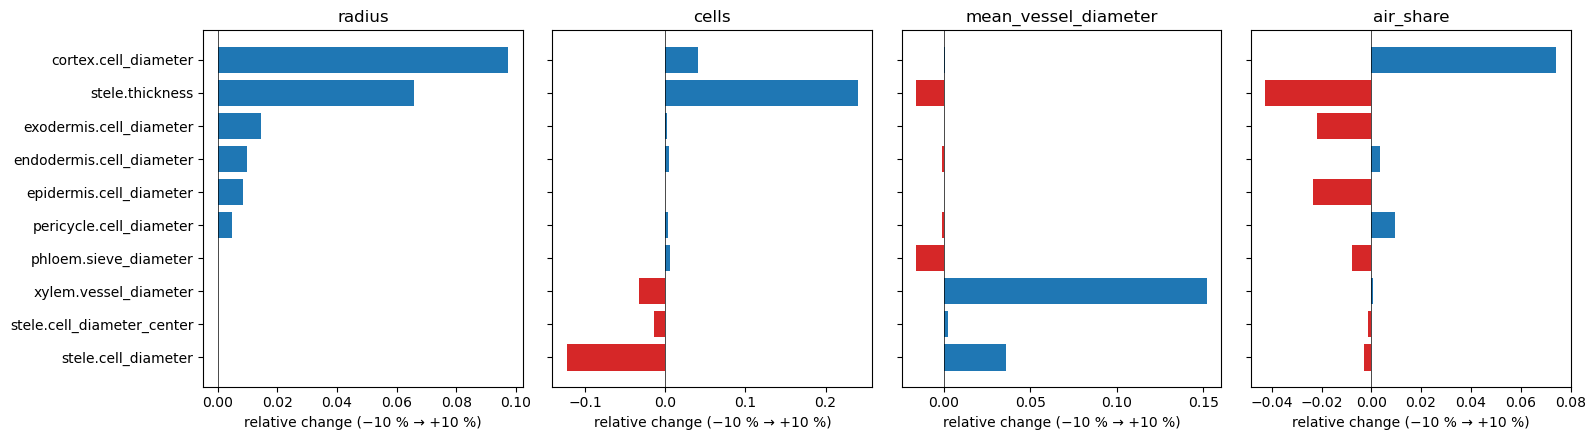

In [2]:
ranked = effects.reindex(effects["radius"].abs().sort_values().index)     # one order: by the radius'
fig, axes = plt.subplots(1, len(OUTPUTS), figsize=(16, 4.5), sharey=True)
for ax, output in zip(axes, OUTPUTS):
    ax.barh(ranked.index, ranked[output], color=np.where(ranked[output] >= 0, "tab:blue", "tab:red"))
    ax.set_title(output); ax.set_xlabel("relative change (−10 % → +10 %)")
    ax.axvline(0, color="k", lw=0.5)
plt.tight_layout()

**Reading the bars** (a "tornado" chart):

- A bar of 0.1 means the output changes by 10 % when the parameter goes from −10 % to +10 %. Blue bars increase the
  output, red ones decrease it.
- The **radius** depends most on the cortex cells' diameter: the cortex is the thickest ring. The stele's diameter
  comes next.
- The **number of cells** depends most on the stele: a wider stele holds more of its small cells, and larger stele
  cells mean fewer of them.
- The **vessels' mean diameter** responds to the metaxylem's diameter.
- The **air share** changes by a few percent: here it is the intercellular spaces between the cortex cells, which
  grow with them.

## 2. Is an effect larger than chance?

The cells are placed at random (tutorial 2). Seed 0 was used above for every section. With another seed the outputs
vary by themselves, so an effect smaller than this variation should not be over-interpreted.

In [3]:
by_seed = pd.DataFrame([simulate(seed=seed).totals[OUTPUTS] for seed in range(1, 6)])
noise = by_seed.std() / by_seed.mean()
print("variation from seed to seed (coefficient of variation):")
print(noise.round(4).to_string())

variation from seed to seed (coefficient of variation):
radius                  0.0000
cells                   0.0035
mean_vessel_diameter    0.0237
air_share               0.0040


The radius does not vary at all from seed to seed: it is set by the parameters. The other outputs vary by a few tenths
of a percent to a few percent: smaller effects than that cannot be told apart from chance with a single seed.

Changing one parameter at a time is simple, but it explores only a cross around the defaults. It misses the
interactions seen in tutorial 3.

## 3. All together: random sampling

Four parameters vary together, each between −20 % and +20 % of its default. A **Latin hypercube** draws 24
combinations that cover each parameter's range evenly. For each output, a linear regression on the standardised
parameters gives **standardised regression coefficients** (SRC):

- the SRC of a parameter is the change of the output, in standard deviations, for a change of one standard deviation
  of the parameter;
- when the regression fits well (R² close to 1), the squared SRCs say which share of the output's variance each
  parameter explains.

Dedicated libraries (for example SALib) offer more methods (Morris, Sobol). The principle stays the same: sample the
parameters, run the model, and relate the outputs to the parameters.

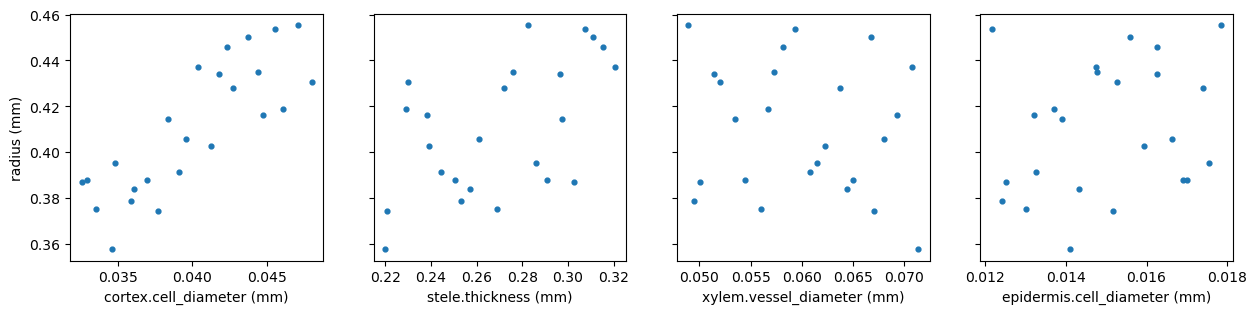

In [4]:
from scipy.stats import qmc

sampled = [("cortex", "cell_diameter"), ("stele", "thickness"), ("xylem", "vessel_diameter"),
           ("epidermis", "cell_diameter")]
names = [f"{section}.{field}" for section, field in sampled]
unit_sample = qmc.LatinHypercube(d=len(sampled), seed=0).random(24)
values = pd.DataFrame(qmc.scale(unit_sample, [0.8 * defaults[key] for key in sampled],
                                [1.2 * defaults[key] for key in sampled]), columns=names)


def changes(row):
    out = {}
    for (section, field), name in zip(sampled, names):
        out.setdefault(section, {})[field] = row[name]
    return out


outputs = pd.DataFrame([simulate(changes(row)).totals[OUTPUTS] for _, row in values.iterrows()])

fig, axes = plt.subplots(1, len(names), figsize=(15, 3.2), sharey=True)
for ax, name in zip(axes, names):
    ax.scatter(values[name], outputs["radius"], s=12)
    ax.set_xlabel(f"{name} (mm)")
axes[0].set_ylabel("radius (mm)");

In [5]:
standardised = (values - values.mean()) / values.std()
design = np.column_stack([np.ones(len(values)), standardised.values])
rows = {}
for output in ["radius", "cells", "mean_vessel_diameter"]:
    y = (outputs[output] - outputs[output].mean()) / outputs[output].std()
    coefficients, *_ = np.linalg.lstsq(design, y.values, rcond=None)
    fitted = design @ coefficients
    r2 = 1 - np.sum((y.values - fitted) ** 2) / np.sum((y.values - y.values.mean()) ** 2)
    rows[output] = dict(zip(names, coefficients[1:]), R2=r2)
pd.DataFrame(rows).T.astype(float).round(2)

,cortex.cell_diameter,stele.thickness,xylem.vessel_diameter,epidermis.cell_diameter,R2
radius,0.82,0.55,0.00,0.07,1.00
cells,0.17,0.97,-0.07,-0.02,0.99
mean_vessel_diameter,0.05,0.06,0.96,0.04,0.92


**Reading the table.** Each row is an output; each column a parameter's SRC; `R2` how well the linear regression fits.
The radius is a sum of the tissues' thicknesses, so the regression explains it almost entirely (R² close to 1). The
cortex cells' size and the stele's diameter share it. The number of cells depends on the stele's diameter, the
vessels' diameter on the metaxylem's diameter alone.
A lower R² would signal a non-linear response or interactions; methods such as Sobol's then quantify them.

## Try it yourself

1. Add the numbers of layers to the one-at-a-time analysis, by ±1 layer instead of ±10 %. Which ring matters most?
2. Add `aerenchyma.aerenchyma_proportion` to the random sample, between 0.1 and 0.3. Which output does it drive?
3. Repeat the one-at-a-time analysis with seed 3 (`simulate(..., seed=3)`): is the ranking the same?

**Next:** `05_experimental_data.ipynb`.